# Run 04: split vs no-split (only the retain data changes)

**Run:** job 2401335. `lapa-12b-instruct`, `--split --loss_positions words --beta 1 --lr 5e-4 --alpha 5`, layer 7 (trained: 5, 6, 7 `down_proj`), 129 steps.

Identical to run 03 (`../03/03.ipynb`) except for `--split`:

| | run 03 (`--no-split`) | run 04 (`--split`) |
|---|---|---|
| forget batch *i* | stereotype sentences of items 4i…4i+3 | **the same** (both shuffle with seed 42; split takes the first half) |
| retain batch *i* | anti-stereotypes of **the same** items (the twins) | anti-stereotypes of **other** items (second half) |
| steps | 257 | 129 (half the items) |

So this is a one-change experiment. **Question:** was run 03's non-selectivity caused by the twins? With twins, the shared prefix ("The" in "The caring / uncaring mother") has identical activations in both losses, so forget and retain pull the same vectors in opposite directions. Without twins, that conflict is gone.

- **If the twins were the cause:** forget and retain should separate here.
- **If not:** the edit is applied to all gender sentences alike, and retain follows forget as before.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

ALPHA = 5.0

d = pd.read_csv("04logs.csv")
run03 = pd.read_csv("../03/03logs.csv").iloc[: len(d)]  # same number of steps

same = d.forget_ids.values == run03.forget_ids.values
print(f"{len(d)} steps, any NaN: {d.drop(columns='forget_ids').isna().any().any()}")
print(f"forget batches identical to run 03: {same.sum()} of {len(d)} (differs at step {list(d.step[~same])})")

129 steps, any NaN: False
forget batches identical to run 03: 128 of 129 (differs at step [128])


## Summary per block of steps

In [2]:
cols = ["unlearn_loss", "unlearn_loss_frozen", "forget_norm_ratio", "retain_norm_ratio",
        "forget_cos_u", "retain_cos_u", "unlearn_cosine_sim", "retain_cosine_sim"]
bins = [-1, 0, 30, 60, 90, 129]
names = ["step 0", "1-30", "31-60", "61-90", "91-128"]

blocks = d.groupby(pd.cut(d.step, bins), observed=True)[cols].mean()
blocks.index = names
blocks.round(4)

,unlearn_loss,unlearn_loss_frozen,forget_norm_ratio,retain_norm_ratio,forget_cos_u,retain_cos_u,unlearn_cosine_sim,retain_cosine_sim
step 0,3132.9167,3132.9167,1.0000,1.0000,0.0015,0.0018,1.0000,1.0000
1-30,2598.6751,3133.7401,0.8358,0.8525,0.0400,0.0387,0.9843,0.9844
31-60,2468.9897,3160.8414,0.8262,0.8483,0.0790,0.0776,0.9866,0.9875
61-90,2496.0684,3165.4574,0.8516,0.8514,0.0884,0.0887,0.9885,0.9788
91-128,2408.3326,3123.8063,0.8365,0.8432,0.0958,0.0945,0.9885,0.9887


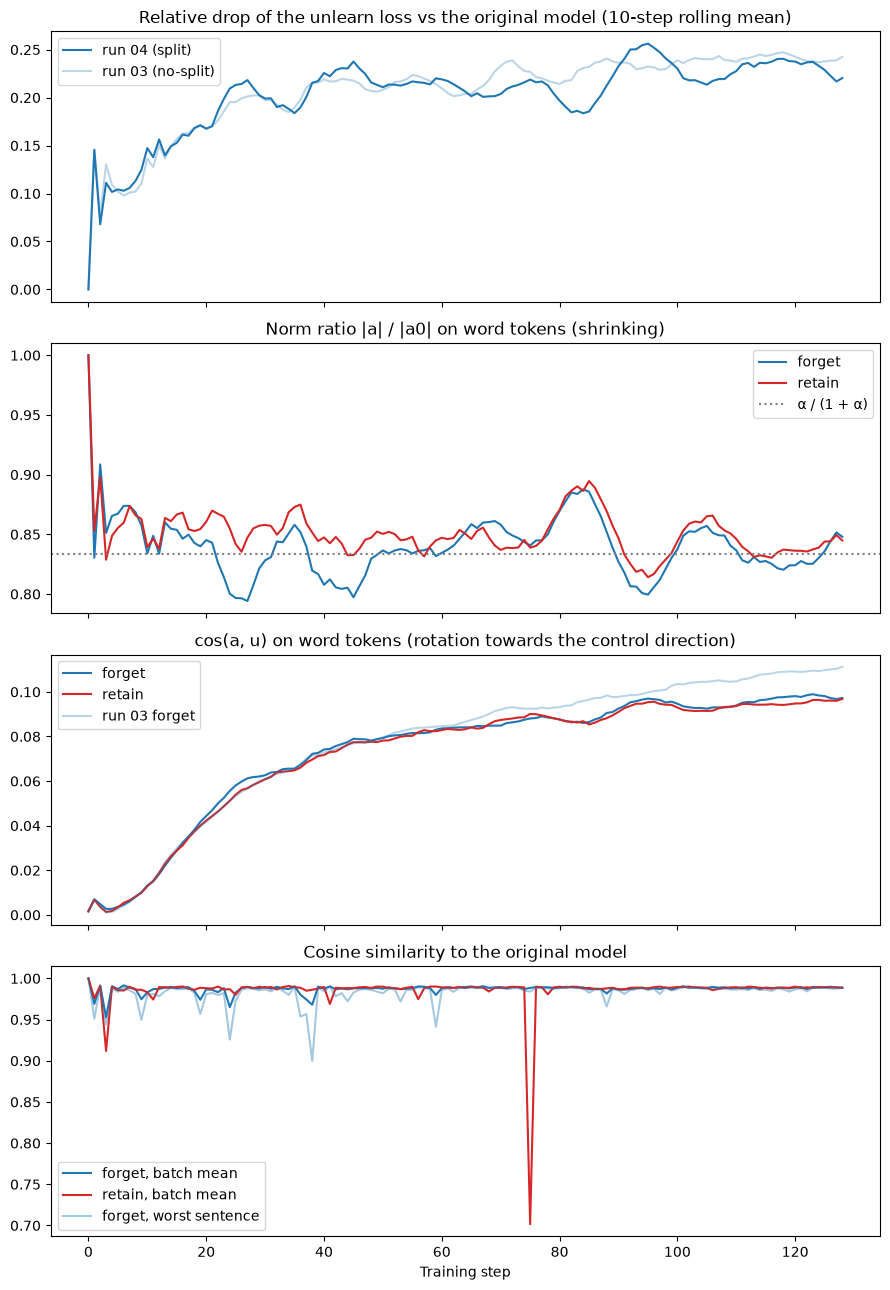

In [3]:
def smooth(s):
    return s.rolling(10, min_periods=1).mean()

FORGET, RETAIN = "tab:blue", "tab:red"
fig, axes = plt.subplots(4, 1, figsize=(9, 13), sharex=True)

ax = axes[0]
ax.plot(d.step, smooth(1 - d.unlearn_loss / d.unlearn_loss_frozen), label="run 04 (split)", color=FORGET)
ax.plot(run03.step, smooth(1 - run03.unlearn_loss / run03.unlearn_loss_frozen),
        label="run 03 (no-split)", color=FORGET, alpha=0.3)
ax.set_title("Relative drop of the unlearn loss vs the original model (10-step rolling mean)")
ax.legend()

ax = axes[1]
ax.plot(d.step, smooth(d.forget_norm_ratio), label="forget", color=FORGET)
ax.plot(d.step, smooth(d.retain_norm_ratio), label="retain", color=RETAIN)
ax.axhline(ALPHA / (1 + ALPHA), color="grey", ls=":", label="α / (1 + α)")
ax.set_title("Norm ratio |a| / |a0| on word tokens (shrinking)")
ax.legend()

ax = axes[2]
ax.plot(d.step, smooth(d.forget_cos_u), label="forget", color=FORGET)
ax.plot(d.step, smooth(d.retain_cos_u), label="retain", color=RETAIN)
ax.plot(run03.step, smooth(run03.forget_cos_u), label="run 03 forget", color=FORGET, alpha=0.3)
ax.set_title("cos(a, u) on word tokens (rotation towards the control direction)")
ax.legend()

ax = axes[3]
ax.plot(d.step, d.unlearn_cosine_sim, label="forget, batch mean", color=FORGET)
ax.plot(d.step, d.retain_cosine_sim, label="retain, batch mean", color=RETAIN)
ax.plot(d.step, d.forget_cos_min, label="forget, worst sentence", color=FORGET, alpha=0.4)
ax.set_title("Cosine similarity to the original model")
ax.set_xlabel("Training step")
ax.legend()

fig.tight_layout()
fig.savefig("04_split_vs_nosplit.png", dpi=120)

## 1. Is the change selective now?

All measured on word tokens, so forget and retain are directly comparable. Run 03 is cut to the same 129 steps.

In [4]:
def summary(df, name):
    late = df.iloc[-30:]
    return {
        "run": name,
        "forget k": late.forget_norm_ratio.mean(),
        "retain k": late.retain_norm_ratio.mean(),
        "forget cos(a,u)": late.forget_cos_u.mean(),
        "retain cos(a,u)": late.retain_cos_u.mean(),
        "corr cos(a,u) f/r": df.forget_cos_u.corr(df.retain_cos_u),
        "relative drop": (1 - late.unlearn_loss / late.unlearn_loss_frozen).mean(),
    }

pd.DataFrame([summary(run03, "run 03, no-split"), summary(d, "run 04, split")]).set_index("run").round(3)

,forget k,retain k,"forget cos(a,u)","retain cos(a,u)","corr cos(a,u) f/r",relative drop
run,,,,,,
"run 03, no-split",0.830,0.841,0.108,0.107,0.998,0.243
"run 04, split",0.839,0.845,0.096,0.095,0.981,0.227


In [5]:
late = d.iloc[-30:]
gap = d.unlearn_cosine_sim - d.retain_cosine_sim
print(f"last 30 steps: forget rotated further than retain in {(late.forget_cos_u > late.retain_cos_u).mean():.0%}, "
      f"shrank more in {(late.forget_norm_ratio < late.retain_norm_ratio).mean():.0%} of steps")
print(f"median forget - retain cosine-to-original gap, last 30 steps: {gap.iloc[-30:].median():.5f}")

last 30 steps: forget rotated further than retain in 70%, shrank more in 63% of steps
median forget - retain cosine-to-original gap, last 30 steps: -0.00011


## 2. Shrinking vs rotation

Same decomposition as before (β = 1, $\cos(a_0, u) \approx 0$): relative drop ≈ $\frac{1-k^2}{2}$ (shrinking, counted first) + $k\cos(a,u)$ (rotation). It's approximate because the columns are batch averages.

In [6]:
for name, df in [("run 03, no-split", run03), ("run 04, split", d)]:
    late = df.iloc[-30:]
    k, cos_u = late.forget_norm_ratio, late.forget_cos_u
    shrink, rotation = ((1 - k**2) / 2).mean(), (k * cos_u).mean()
    measured = (1 - late.unlearn_loss / late.unlearn_loss_frozen).mean()
    print(f"{name}: measured {measured:.1%} = shrinking {shrink:.1%} + rotation {rotation:.1%} "
          f"(sum {shrink + rotation:.1%}; shrinking {shrink / (shrink + rotation):.0%})")

run 03, no-split: measured 24.3% = shrinking 15.5% + rotation 9.0% (sum 24.5%; shrinking 63%)
run 04, split: measured 22.7% = shrinking 14.7% + rotation 8.0% (sum 22.8%; shrinking 65%)


## Conclusions

1. **Removing the twins did not make the edit selective.** Forget and retain shrink by the same amount (k ≈ 0.84 vs 0.85) and rotate by the same amount (cos(a, u) ≈ 0.096 vs 0.095). The two cos(a, u) curves correlate at 0.98 (run 03 over the same 129 steps: 0.998). The cosine-to-original gap is ≈ 0. Forget is ahead of retain in only 60–70% of the last 30 steps, and by tiny margins.
2. **So the shared-prefix conflict was not the main cause** of run 03's non-selectivity. This matches pilot run #6 (split did not separate forget and retain either). Even when the retain sentences are completely different items, they change exactly like the forget sentences.
3. **The balance k ≈ α/(1+α) = 0.83 still holds**, now between *different* sentences. That supports the explanation that the model learns **one change for all gender sentences**: the forget term pushes it, the retain term (on other sentences) pulls it back, and they settle at the balance.
4. **Slightly less rotation than run 03** at the same step count (cos(a, u) ≈ 0.096 vs ≈ 0.11). Shrinking is again ≈ 65% of the drop. With twins, the retain term was fighting the forget term on the same prefix vectors; here it isn't, but the overall result is almost the same.
5. **No large dips.** The worst sentence stays ≥ 0.90 (run 03 had a sentence fall to 0.40). The forget-only dips in run 03 may have come from specific batches late in the run (steps 185–255), which this 129-step run never reaches.

**What it means:** at layer 7, the model's edit doesn't separate stereotype from anti-stereotype sentences, whether or not they're twins. Open question: does the same edit also hit **non-gender text**? Retain is also gender sentences, so we can't tell. Logging `retain_norm_ratio` on neutral text (e.g. StereoSet's other bias types, or Wikipedia) would show whether the edit is "gender-specific" or just "everything at layer 7".